In [1]:
import numpy as np
import numpy as np
from scipy import special
from scipy.special import erfc, erfi
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path

from scipy.special import erfc, erfcx, erf
from cdm_ewald.CDM_Ewald_direct import CDM_Ewald_direct

In [2]:
# parameters
# import silver dielectric constant
optical_data = pd.read_csv(
    "silver_optical_data.csv"
)
# Original data

wavelength_orig = optical_data["lambda"].to_numpy()

epsP_orig = optical_data["e1"].to_numpy() + 1j * optical_data["e2"].to_numpy()

# Add new wavelengths

add_wavelength_list = np.arange(470/50, 490/50, 0.1)  # 470, 475, 480, 485

# Merge and sort uniquely

wavelength_list = np.unique(

    np.concatenate((wavelength_orig, add_wavelength_list))

)

# Interpolate the real and imaginary parts separately

epsP = (

    np.interp(wavelength_list, wavelength_orig, epsP_orig.real)

    + 1j * np.interp(wavelength_list, wavelength_orig, epsP_orig.imag)

)

# Other quantities

k_list = 2 * np.pi / wavelength_list

k_direction = np.array([0, 0, 1])
def phi_1(x):
    return np.sin(x)/x - np.cos(x)
def xi_1(x):
    return np.sin(x)/x - np.cos(x) + 1j*(-np.cos(x) - np.sin(x)/x)
def phi_1_prime(x):
    return -np.sin(x)/x**2 + np.cos(x)/x + np.sin(x)
def xi_1_prime(x):
    return -np.sin(x)/x**2 + np.cos(x)/x + np.sin(x) + 1j*(np.cos(x)/x**2 + np.sin(x)/x - np.cos(x))
x_array = k_list
m_array = np.sqrt(epsP)
a1_array_up = m_array*phi_1(m_array*x_array)*phi_1_prime(x_array)-phi_1(x_array)*phi_1_prime(m_array*x_array)
a1_array_down = m_array*phi_1(m_array*x_array)*xi_1_prime(x_array)-xi_1(x_array)*phi_1_prime(m_array*x_array)
a1_array = a1_array_up/a1_array_down
polarizability_list = 1j*1.5*a1_array/(x_array**3) * 4 * np.pi
wavelength_nm = wavelength_list * 50


In [3]:
# build lattice
lattice_type = "square"
positions = np.array([[0,0,0]])
wavevector_direction = np.array([0,0,1]) # z
polarization_direction = np.array([1,0,0]) # x
particle_raiuds = 50 # nm
lattice_constant = 470 / 50 # 470 nm
if lattice_type == "square":
    v1 = np.array([lattice_constant, 0.0])
    v2 = np.array([0.0, lattice_constant])
    lattice_vectors = np.stack((v1,v2),axis=1)
elif lattice_type == "hexagonal":
    v1 = np.array([lattice_constant, 0.0])
    v2 = np.array([0.5 * lattice_constant, np.sqrt(3) * lattice_constant / 2])
    lattice_vectors = np.stack((v1,v2),axis=1)

In [4]:
cdm = CDM_Ewald_direct(lattice_vectors,positions,polarizability_list,k_list, wavevector_direction,polarization_direction)

In [5]:
cdm.compute()

ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape (3, 1)
ashape (3, 3) eshape

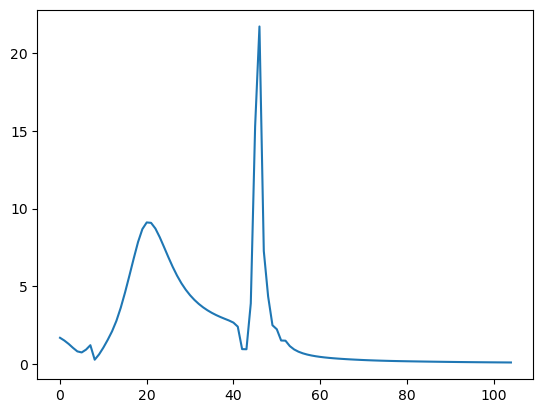

In [6]:
plt.plot(cdm.extinction_efficiency)

In [7]:
cdm.extinction_efficiency.shape

(105, 1)